<a href="https://colab.research.google.com/github/DanDC25/Statistical-Learning-with-Python/blob/main/%5BLAB%5D_DSA211_09_Lab_Regularisation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Part 0: Setup and Data

In the lecture we regularised the `Hitters` salary model. In this lab you run the same workflow on the `Credit` dataset. You diagnosed the `Limit`/`Rating` collinearity with VIF in Week 4 and watched selection methods handle it in Week 8. Regularisation is the remedy promised in Week 4.

The workflow: split once, make every decision by CV on the training set, touch the test set once, refit on all the data.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import variance_inflation_factor
from sklearn.linear_model import (LinearRegression, Ridge, Lasso, ElasticNet,
                                  RidgeCV, LassoCV)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.metrics import mean_squared_error

np.random.seed(2026)

The `Credit` dataset: 400 credit card holders, response `Balance` (average card balance in dollars), with income, credit limit, credit rating, and demographic predictors. After dummy encoding there are 11 predictors.

In [ ]:
url = 'https://raw.githubusercontent.com/intro-stat-learning/ISLP/main/ISLP/data/Credit.csv'
credit = pd.read_csv(url).drop(columns='ID')
credit.index = range(1, len(credit) + 1)

X = pd.get_dummies(credit.drop(columns='Balance'), drop_first=True).astype(float)
y = credit['Balance']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=2026)

print(X.shape)
print(f'Training: {len(X_train)} card holders, test: {len(X_test)} card holders')

(400, 11)
Training: 280 card holders, test: 120 card holders


EDA happens after the split, on the training set only.

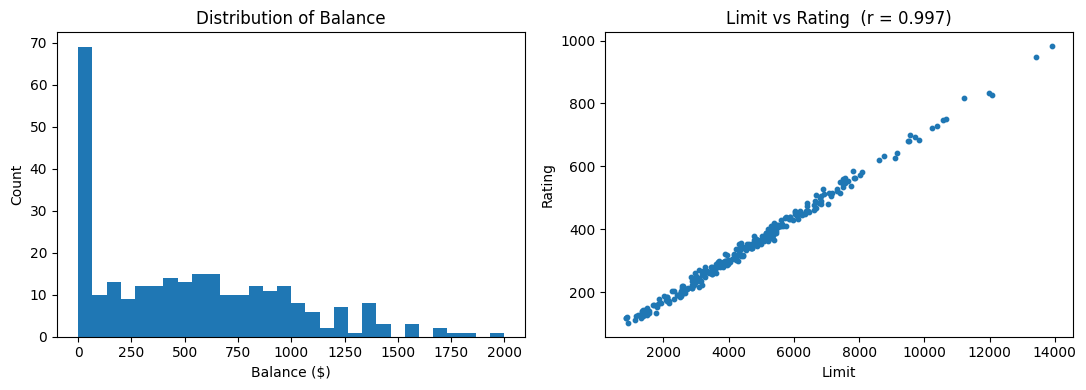

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(y_train, bins=30)
axes[0].set_xlabel('Balance ($)')
axes[0].set_ylabel('Count')
axes[0].set_title('Distribution of Balance')

axes[1].scatter(X_train['Limit'], X_train['Rating'], s=10)
axes[1].set_xlabel('Limit')
axes[1].set_ylabel('Rating')
axes[1].set_title(f"Limit vs Rating  (r = {X_train['Limit'].corr(X_train['Rating']):.3f})")

plt.tight_layout()
plt.show()

`Limit` and `Rating` are effectively the same variable measured twice. A credit rating is largely computed from the limit a bank is willing to extend. Confirm with VIF.

In [ ]:
Xc = sm.add_constant(X_train)
vifs = pd.Series(
    [variance_inflation_factor(Xc.values, i) for i in range(1, Xc.shape[1])],
    index=X.columns, name='VIF'
)
vifs.sort_values(ascending=False).round(1)

,VIF
Rating,247.1
Limit,246.7
Income,2.9
Ethnicity_Asian,1.5
Ethnicity_Caucasian,1.5
Cards,1.5
Age,1.1
Married_Yes,1.1
Education,1.1
Student_Yes,1.0


VIFs above 200 for both `Limit` and `Rating`, far beyond the "severe" threshold of 10. Everything else is clean. One tightly collinear pair inside an otherwise well-behaved design. This is a different profile from `Hitters`, where a whole block of career statistics was entangled. Keep that difference in mind, it explains Part 4.

***

## Part 1: Ridge Regression

### 1.1 Ridge and the Collinear Pair

Standardise the predictors first, since the penalty is not scale-invariant. To avoid leakage, learn the means and SDs from the training set only.

We repeat the lecture's half-sample experiment. OLS and ridge ($\lambda = 100$) are each refitted on 100 random half-samples of the training set. The table records the mean and SD of the `Limit` and `Rating` coefficients of the 100 iterations.

In [ ]:
scaler = StandardScaler()
Xs_train = scaler.fit_transform(X_train)

rng = np.random.default_rng(2026)
halves = [rng.choice(len(X_train), size=len(X_train) // 2, replace=False) # half-samples
          for _ in range(100)]

summary = {}
difference = {}
for name, est in [('OLS', LinearRegression()), ('Ridge (lambda = 100)', Ridge(alpha=100))]:
    pipe = Pipeline([('scaler', StandardScaler()),
                     ('model', est)])
    coefs = pd.DataFrame([pipe.fit(X_train.iloc[idx], y_train.iloc[idx])['model'].coef_
                          for idx in halves], columns=X.columns)[['Limit', 'Rating']]
    summary[(name, 'mean')] = coefs.mean()
    summary[(name, 'SD')] = coefs.std()


pd.DataFrame(summary).round(1)




OLS        Ridge (lambda = 100)     
         mean     SD                 mean   SD
Limit   312.5  116.5                146.8  5.2
Rating  288.3  115.7                147.7  5.1

❓ **Question 1.1.** By how much does ridge reduce the half-sample SD of the `Limit` and `Rating` coefficients? The mean coefficients move too. What is ridge giving up in exchange for the lower SD?

Keep your answer in mind. Part 4 asks whether this instability actually hurts OLS's predictions.

*Your answer here:*

The ridge regerssion reduces the half-sample SD of both coefficients from around 116 to around 5 standard deviation.

Ridge regression is, in fact, a less complex model than OLS model. Hence, in order to achieve a lower standard deviation (and variance), the model allows for an increase in Bias. To do so, ridge regression adds a penalty (lamda * I) to the matrix to stabilize the inverse, avoiding an inflation of variance when the matrix is near to being singular.

### 1.2 The Ridge Path

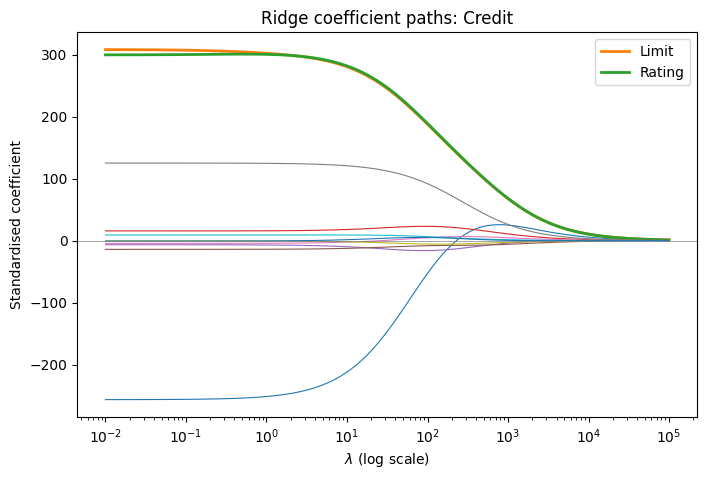

In [ ]:
lambdas = np.logspace(-2, 5, 100)
ridge_path = np.array([Ridge(alpha=l).fit(Xs_train, y_train).coef_ for l in lambdas])

fig, ax = plt.subplots(figsize=(8, 5))
for j, name in enumerate(X.columns):
    hl = name in ['Limit', 'Rating']
    ax.plot(lambdas, ridge_path[:, j], linewidth=2 if hl else 0.8, label=name if hl else None)
ax.set_xscale('log')
ax.axhline(0,
           color='grey',
           linewidth=0.5)
ax.set_xlabel(r'$\lambda$ (log scale)')
ax.set_ylabel('Standardised coefficient')
ax.set_title('Ridge coefficient paths: Credit')
ax.legend()
plt.show()

❓ **Question 1.2.** Suppose `Limit` and `Rating` together must contribute 600 to the prediction. Ridge charges $\beta_{\text{Limit}}^2 + \beta_{\text{Rating}}^2$ for it. Compare the cost of splitting it 600 and 0 with splitting it 300 and 300. Use this to explain why the two paths in the plot travel together.

*Your answer here:*

The penalty for both splits are different. The cost of splitting 600 - 0 would be 600^2 = 360000 whereas the cost of splitting evenly 300 - 300 = 180000, half of the penalty of the first option.

Both **Limit** and **Rating** carry nearly the same information (collinearity), while RSS remains the same, penalty does not, and the 300 - 300 split does not overstate the penalty

The two paths move together as they are collinear - having almost indentical RSS; hence, their coefficients (the two paths) move together.





***

## Part 2: The LASSO

### 2.1 LASSO Paths and Sparsity

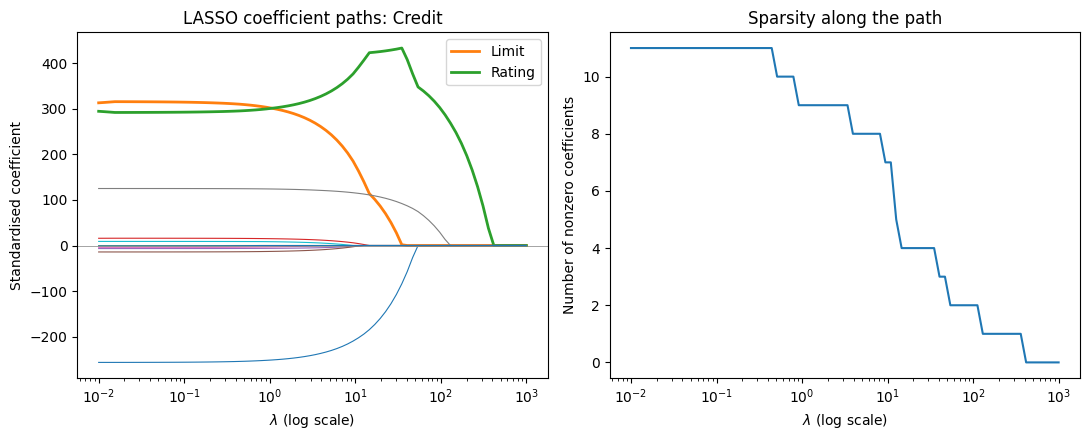

In [ ]:
alphas = np.logspace(-2, 3, 80)
lasso_path = np.array([Lasso(alpha=a, max_iter=100000).fit(Xs_train, y_train).coef_
                       for a in alphas])

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for j, name in enumerate(X.columns):
    hl = name in ['Limit', 'Rating']
    axes[0].plot(alphas, lasso_path[:, j], linewidth=2 if hl else 0.8, label=name if hl else None)
axes[0].set_xscale('log')
axes[0].axhline(0, color='grey', linewidth=0.5)
axes[0].set_xlabel(r'$\lambda$ (log scale)')
axes[0].set_ylabel('Standardised coefficient')
axes[0].set_title('LASSO coefficient paths: Credit')
axes[0].legend()

axes[1].plot(alphas, (np.abs(lasso_path) > 1e-10).sum(axis=1))
axes[1].set_xscale('log')
axes[1].set_xlabel(r'$\lambda$ (log scale)')
axes[1].set_ylabel('Number of nonzero coefficients')
axes[1].set_title('Sparsity along the path')

plt.tight_layout()
plt.show()

### Exercise 2.1: When does each predictor enter?

Read right to left, the path is a selection order: as $\lambda$ falls, predictors enter one at a time. Find, for every predictor, the largest $\lambda$ at which its coefficient is nonzero. That is where it enters.

In [ ]:
### YOUR CODE HERE
# Task: build the LASSO entry order.
#
# 1. nonzero = np.abs(lasso_path) > 1e-10      (rows: lambdas, columns: predictors)
# 2. For each column, the largest alpha where nonzero is True:
#    (alphas[:, None] * nonzero).max(axis=0)
# 3. Store it as a pd.Series named `entry`, indexed by X.columns,
#    sorted from the largest lambda to the smallest; display it rounded to 1 dp

nonzero = np.abs(lasso_path) > 1e-10
lambdaa = (alphas[:, None] * nonzero).max(axis=0)
entry = pd.Series(lambdaa.round(2), index=X.columns).sort_values(ascending=False)
print(entry)

#entry = pd.DataFrame({
#   'LASSO: Predictors enter at λ=': entry_series.round(2)
#}, index=(X.columns))
#print(entry)


Rating                 360.55
Student_Yes            112.37
Income                  46.87
Limit                   35.02
Cards                   12.63
Education               10.91
Age                     10.91
Ethnicity_Asian          8.15
Gender_Female            3.40
Ethnicity_Caucasian      0.79
Married_Yes              0.44
dtype: float64


❓ **Question 2.1.** `Rating` and `Limit` enter at very different values of $\lambda$. Which enters first? At what $\lambda$ does the other one join it? A classmate concludes that the late entrant "doesn't matter for credit card balance". Correct them, using the lecture's discussion of what the LASSO does with correlated predictors.

*Your answer here:*

Rating and Limit enters at different values of lambda, depending on which is first to become non-zero. As lambda decreases from its maximum value to the minimum value, **Rating** enters first (at lambda ≈ 360), and **Limit** enters after (at lambda ≈ 46).

### 2.2 LASSO versus Forward Stepwise

Week 8's forward stepwise also produces an entry order. The cell below reruns Lab 8's forward search, this time on the training set, and lines the two orders up.

In [ ]:
remaining, order = list(X.columns), []
while remaining:
    best = min(remaining, key=lambda v: sm.OLS(
        y_train, sm.add_constant(X_train[order + [v]])).fit().ssr)
    order.append(best)
    remaining.remove(best)

pd.DataFrame({'forward stepwise': order, 'LASSO': entry.index},
             index=pd.RangeIndex(1, len(order) + 1, name='step'))

,forward stepwise,LASSO
step,,
1,Rating,Rating
2,Income,Student_Yes
3,Student_Yes,Income
4,Limit,Limit
5,Cards,Cards
6,Education,Education
7,Ethnicity_Asian,Age
8,Age,Ethnicity_Asian
9,Gender_Female,Gender_Female


❓ **Question 2.2.** The two orders agree on `Rating` first and `Limit` fourth, but swap `Income` and `Student_Yes`. Forward stepwise and the LASSO both build a sequence of models. State one way in which the two procedures differ in *how* they add a variable, and explain why that difference allows the orders to disagree.

*Your answer here:*

ALthough forward stepwise and LASSO both build sequences of models, the procedures in which predictors are selected for their models differ. Specifically, forward stepwise is greedy, all of its models are nested and predictors that is included in the model can't be removed. Forward stepwise selects predictors (subsequently models) that reduces RSS the most.

LASSO, on the other hand, is able to reverse an addition of a predictor from its models. Predictors are added/removed based on lambda, specifically, the highest value of lambda in which the predictor is non-zero.

The difference in **how predictors are selected** results in a difference in orders as a predictor may have the largest reduction in RSS, but its coefficients may not be the first to become non-zero as lambda run from largest to smallest.

***

## Part 3: Choosing $\lambda$ by Cross-Validation

Standardisation is learned from data, so it must be fitted inside each training fold using a `Pipeline`. All tuning uses 5-fold CV on the training set.

In [ ]:
pipe = Pipeline([('scaler', StandardScaler()),
                 ('lasso', Lasso(max_iter=100000))])

alpha_grid = np.logspace(-3, 3, 60) # lasso penalties

K = 5
cv = KFold(n_splits=K,
           shuffle=True,
           random_state=2026)

### 3.1 The CV Error Curve

Use the SE definition from the lecture: $\text{SE} = s/\sqrt{K}$ with `ddof=1`. `sklearn`'s `std_test_score` uses `ddof=0`, so divide it by $\sqrt{K-1}$.

In [ ]:
search = GridSearchCV(pipe,
                      {'lasso__alpha': alpha_grid},
                      cv=cv,
                      scoring='neg_mean_squared_error')
search.fit(X_train, y_train);

cv_mse = -search.cv_results_['mean_test_score']
cv_se = search.cv_results_['std_test_score'] / np.sqrt(K - 1)   # = s / sqrt(K), ddof=1

i_min = cv_mse.argmin()
lambda_min = alpha_grid[i_min]
threshold = cv_mse[i_min] + cv_se[i_min]
lambda_1se = alpha_grid[cv_mse <= threshold].max()

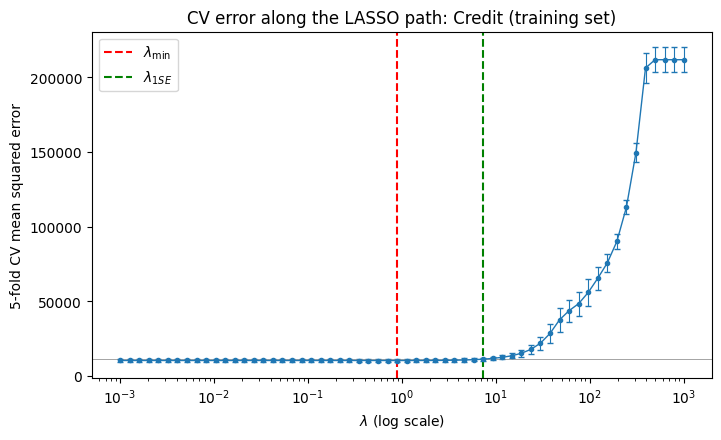

lambda (min):  0.890   CV RMSE 102.2
lambda (1-SE): 7.32    CV RMSE 106.5


In [ ]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.errorbar(alpha_grid,
            cv_mse,
            yerr=cv_se,
            fmt='o-',
            markersize=3,
            linewidth=1,
            elinewidth=0.8,
            capsize=2)
ax.axvline(lambda_min,
           color='red',
           linestyle='--',
           label=r'$\lambda_{\min}$')
ax.axvline(lambda_1se,
           color='green',
           linestyle='--',
           label=r'$\lambda_{1SE}$')
ax.axhline(threshold,
           color='grey',
           linewidth=0.5)
ax.set_xscale('log')
ax.set_xlabel(r'$\lambda$ (log scale)')
ax.set_ylabel('5-fold CV mean squared error')
ax.set_title('CV error along the LASSO path: Credit (training set)')
ax.legend()
plt.show()

print(f'lambda (min):  {lambda_min:.3f}   CV RMSE {np.sqrt(cv_mse[i_min]):.1f}')
print(f'lambda (1-SE): {lambda_1se:.2f}    CV RMSE {np.sqrt(cv_mse[alpha_grid == lambda_1se][0]):.1f}')

❓ **Question 3.1.** The CV curve is almost flat from the left edge of the grid up to $\lambda_{\min}$, then rises. What does a flat curve at small $\lambda$ tell you about how much this dataset needs regularisation? Compare with the lecture's `Hitters` curve, which had a clear minimum well inside the grid.

*Your answer here:*

In the graph displaying CV error along the LASSO path as lambda increases, it appears that from lamba = 10^-3 to 10^1, the CV MSE curve is flat. There may be 2 reasons this occur: (1) This dataset, to small extent, this data set needs regularization. In other words, this dataset does not necessarily need regularization as the CV MSE does not appear to change much even when lambda (directly proportional to coefficients' penalty) increases by 10^4. (2) Perhaps the CV MSE curve appear to be flat because the y-axis is zoomed out, creating the illusion of little-change in CV MSE.

Assuming the former, the flat curve at small $\lambda$ indicate that the dataset does not need regularization to a large extent.

### 3.2 The One-Standard-Error Model

### Exercise 3.2: What survives at $\lambda_{1SE}$?

In [ ]:
# Task: fit the 1-SE model on the training set and inspect what survives.
#
# 1. pipe.set_params(lasso__alpha=lambda_1se), then fit on (X_train, y_train)
#    (step__parameter naming, as in Lesson 7's poly_pipe)
# 2. coef_1se = pd.Series(pipe['lasso'].coef_, index=X.columns)
# 3. Display only the nonzero ones (|coef| > 1e-10), rounded to 1 dp

### YOUR CODE HERE
step_parameter = pipe.set_params(lasso__alpha=lambda_1se)
step_parameter.fit(X_train, y_train)

coef_1se = pd.Series(pipe['lasso'].coef_, index=X.columns)

nonzero_coefs = coef_1se[coef_1se.abs() > 1e-10].round(1)
display(nonzero_coefs)
print(nonzero_coefs.index.tolist())

,0
Income,-220.2
Limit,214.6
Rating,357.7
Cards,8.3
Age,-3.1
Education,-5.3
Student_Yes,117.9
Ethnicity_Asian,2.0


['Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education', 'Student_Yes', 'Ethnicity_Asian']


❓ **Question 3.2.** How many predictors does the 1-SE model keep? Are both `Limit` and `Rating` among them? A colleague asks you to report "the effect of income on balance in dollars per \$1,000 of income" from this model. Give two reasons from the lecture (Sections 2.5 and 6) why you should decline, even after undoing the standardisation.

*Your answer here:*

After searching for the model with 1-SE in CV MSE from the minimum CV MSE, 8 predictors are left: 'Income', 'Limit', 'Rating', 'Cards', 'Age', 'Education', 'Student_Yes', 'Ethnicity_Asian'.

When this colleague asks me regarding effect, this is statistical inferences. I am unable to answer and should decline for 2 reasons:
(1) the coefficients on a standardized scale among all units of predictors, it's effects can't be compared unless divided again by SD. Granted, even then, (2) the estimate is shrunk to be used for prediction, and not statistical inferences. Hence, it shouldn't be used for inferences accordingly to the colleague's question.

### 3.3 `RidgeCV` and `LassoCV`

`sklearn` offers estimators with the $\lambda$ search built in. They take the data as given, so the usual pattern scales the whole training set first and only then cuts the folds (leaky). The cell below runs both on the pre-scaled `Xs_train`, on the same folds and grid, against the leakage-free pipeline searches.

`RidgeCV` scores by $R^2$ unless told otherwise, so pass `scoring='neg_mean_squared_error'` to compare like with like.

In [ ]:
ridge_search = GridSearchCV(Pipeline([('scaler', StandardScaler()),
                                      ('ridge', Ridge())]),
                            {'ridge__alpha': alpha_grid},
                            cv=cv, scoring='neg_mean_squared_error').fit(X_train, y_train)

ridge_cv = RidgeCV(alphas=alpha_grid,
                   cv=cv,
                   scoring='neg_mean_squared_error').fit(Xs_train, y_train)
lasso_cv = LassoCV(alphas=alpha_grid,
                   cv=cv,
                   max_iter=100000).fit(Xs_train, y_train)

pd.DataFrame({'Pipeline + GridSearchCV': [ridge_search.best_params_['ridge__alpha'], lambda_min],
              'RidgeCV / LassoCV (pre-scaled)': [ridge_cv.alpha_, lasso_cv.alpha_]},
             index=['Ridge', 'LASSO']).round(3)

,Pipeline + GridSearchCV,RidgeCV / LassoCV (pre-scaled)
Ridge,0.557,0.557
LASSO,0.890,0.890


On `Credit` the shortcuts and the pipelines choose the same $\lambda$. The leak is still there, but it is too small to move the choice: with 224 rows in each training fold, the means and SDs barely change from one fold to another. The lecture's `Hitters` search, on 147 players per training fold with heavy-tailed career statistics, did move: 16.0 with the pipeline against 11.0 with `LassoCV`.

- For quick exploration: the shortcuts are fine.
- For reported results: `Pipeline` + `GridSearchCV`.

***

## Part 4: Comparison, Test, Refit

### 4.1 The Comparison Table

Every candidate is tuned on the same training folds. The elastic net's `l1_ratio` is fixed at 0.5.

In [ ]:
enet_search = GridSearchCV(Pipeline([('scaler', StandardScaler()),
                                     ('enet', ElasticNet(l1_ratio=0.5, max_iter=100000))]),
                           {'enet__alpha': alpha_grid},
                           cv=cv, scoring='neg_mean_squared_error').fit(X_train, y_train)

ols_mse = -cross_val_score(Pipeline([('scaler', StandardScaler()),
                                     ('ols', LinearRegression())]),
                           X_train, y_train, cv=cv, scoring='neg_mean_squared_error')

def n_used(fitted_pipe):
    return int((np.abs(fitted_pipe[-1].coef_) > 1e-10).sum())

rows = [('OLS', ols_mse.mean(), X.shape[1]),
        ('Ridge (min)', -ridge_search.best_score_, n_used(ridge_search.best_estimator_)),
        ('LASSO (min)', cv_mse[i_min], n_used(search.best_estimator_)),
        ('LASSO (1-SE)', cv_mse[alpha_grid == lambda_1se][0], n_used(pipe)),
        ('Elastic net (min)', -enet_search.best_score_, n_used(enet_search.best_estimator_))]

pd.DataFrame([(m, round(np.sqrt(mse), 1), k) for m, mse, k in rows],
             columns=['Model', 'CV RMSE', 'Predictors used']).set_index('Model')

,CV RMSE,Predictors used
Model,,
OLS,102.3,11
Ridge (min),102.1,11
LASSO (min),102.2,9
LASSO (1-SE),106.5,8
Elastic net (min),102.1,11


❓ **Question 4.1.** In the lecture, the tuned ridge, LASSO and elastic net beat OLS on `Hitters` by about 4–5% in CV RMSE. Here OLS ties the best regularised models. Both datasets have severe collinearity, so why the difference? Consider $n$, $p$, and what collinearity damages.

*Your answer here:*

When the number of observations outweighs the number of predictors to a large extent, the sample, inherently, has low variance and a penalty for coefficients isn't necessary. Therefore, even if lambda increases, the test errors doesn't change significantly similar to chapter 3.1 in the lab.

Moreover collinearity affects the individual coefficient estaimtes, but does not affect the model's overall MSE. Hence, models may appear to be similar in terms of CV MSE.

### 4.2 Test Once, Then Refit

Decide what to carry forward before the test set is seen. Then touch it once.

❓ **Question 4.2a.** Using only the CV evidence in your table, which model do you carry forward, and why?

*Your answer here:*

I initially thought to carry the Elastic Net model because it possesses the least CV RMSE and of its advantages. However, after consulting with Gemini, I believe that the differences in CV RMSE to OLS model is negligible and adds additional layers of complexity.



### Exercise 4.2: One test touch, two final refits

In [ ]:
ols = Pipeline([
    ('scaler', StandardScaler()),
    ('ols', LinearRegression())
])
ols.fit(X_train, y_train)

ols_CV_RMSE = np.sqrt(ols_mse.mean())
ols_test_RMSE = np.sqrt(mean_squared_error(y_test, ols.predict(X_test)))

final_lasso = Pipeline([
    ('scaler', StandardScaler()),
    ('lasso', Lasso(alpha=lambda_1se, max_iter=100000))
])
final_lasso.fit(X_train, y_train)  # Fit on train to evaluate true test performance first
lasso_test_RMSE = np.sqrt(mean_squared_error(y_test, final_lasso.predict(X_test)))

# Now refit both models on ALL the data (X, y) as required for the final step
ols.fit(X, y)
final_lasso.fit(X, y)

error = pd.DataFrame({
    'OLS CV RMSE': ols_CV_RMSE,
    'OLS Test RMSE': ols_test_RMSE,
    'LASSO Test RMSE': lasso_test_RMSE
}, index=[0])
print(f'Here is the difference between RMSE of OLS on Cross-Validation and single-test-touch \n {error}')

coefficients = pd.DataFrame({
    'OLS Coefficients': ols['ols'].coef_,
    'LASSO Coefficients': final_lasso['lasso'].coef_
}, index=X.columns)

print(coefficients.sort_values(by=['LASSO Coefficients'], ascending=False))

Here is the difference between RMSE of OLS on Cross-Validation and single-test-touch 
    OLS CV RMSE  OLS Test RMSE  LASSO Test RMSE
0   102.303329     104.994564       111.339053
                     OLS Coefficients  LASSO Coefficients
Limit                      440.099553          367.938037
Rating                     175.628144          212.994425
Student_Yes                127.724208          119.241278
Cards                       24.274738           16.248222
Ethnicity_Asian              7.324290            0.000000
Gender_Female               -5.323360           -0.000000
Education                   -3.429855           -0.000000
Ethnicity_Caucasian          5.053449            0.000000
Married_Yes                 -4.157540           -0.000000
Age                        -10.576563           -5.851743
Income                    -274.670668         -240.794770


❓ **Question 4.2b.** Two clients. Client A wants the most accurate balance predictions to feed a downstream system. Client B is a bank that must explain its balance model to a regulator in one page. Which of your two refits do you hand each client, and which number do you report to each as the expected prediction error?

*Your answer here:*

In my opinion, I believe that I will hand the OLS model to Client A and the LASSO model to client B. This is because the OLS model employs more predictors than the LASSO model and produces the least test error, in other words, the most accuarte balance predictions.

The balance model employing LASSO is shorter and is more likely to be explained "in one page" because it employs less predictors than the OLS model.

The balance model employing OLS would have a more accurate balance predictions because it produces the least test RMSE.

When reporting expected prediction error, I would use the test RMSE found above of each model.


***

## Lab Checklist

Before submitting, confirm you have:

- [ ] Run all demo cells without errors
- [ ] Answered Questions 1.1 and 1.2
- [ ] Completed Exercise 2.1 (LASSO entry order) and answered Questions 2.1 and 2.2
- [ ] Answered Question 3.1
- [ ] Completed Exercise 3.2 (the 1-SE model) and answered Question 3.2
- [ ] Answered Question 4.1
- [ ] Answered Question 4.2a, completed Exercise 4.2 (one test touch, two final refits) and answered Question 4.2b